# Assignment 2: Data Mining, Modeling and Analytics
## Project 1: Wholesale Customer Segmentation

### Objective
To segment wholesale customers according to their annual spending
behaviour, compare clustering algorithms, and recommend appropriate
business strategies for the identified customer segments.

### 1. Exploratory Data Analysis and Data Preparation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [2]:
# Loading the wholesale customers dataset
df = pd.read_csv("wholesale-customers.csv")

# Examining the dataset
print("Dataset shape:", df.shape)

display(df.head())


Dataset shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("\nData types and missing values:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate observations:", df.duplicated().sum())


Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values:


Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64


Duplicate observations: 0



### 1.1 Dataset Overview

The dataset contains 440 wholesale customers and eight variables. Six variables represent annual expenditure on Fresh, Milk, Grocery, Frozen, Detergents_Paper, and Delicatessen products, while Channel and Region describe customer categories. All variables are recorded as integers, with no missing values or duplicate observations. Consequently, no imputation or duplicate removal is required. Customer segmentation will initially be based on the six spending variables, while Channel and Region will be retained for cluster interpretation.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


Skewness of spending variables:


Fresh                2.56
Milk                 4.05
Grocery              3.59
Frozen               5.91
Detergents_Paper     3.63
Delicatessen        11.15
dtype: float64

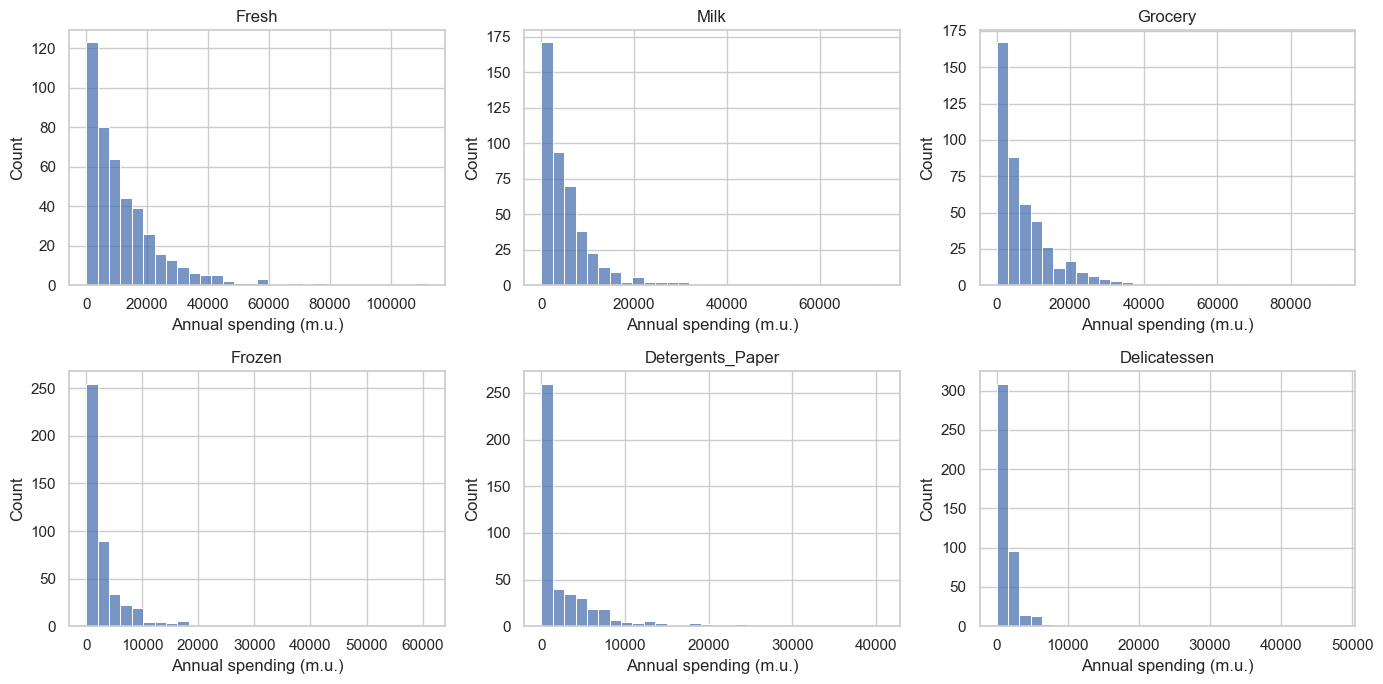

In [10]:

spending_cols = [
    "Fresh", "Milk", "Grocery",
    "Frozen", "Detergents_Paper", "Delicatessen"
]

# Descriptive statistics for the six spending variables
display(df[spending_cols].describe().round(2))

# Measure skewness
print("Skewness of spending variables:")
display(df[spending_cols].skew().round(2))

# Visualize spending distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, col in zip(axes.flat, spending_cols):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Annual spending (m.u.)")

plt.tight_layout()
plt.show()

### 1.2 Descriptive Statistics and Distribution Analysis

Descriptive statistics reveal substantial variation in annual customer expenditure across the six product categories. Fresh products recorded the highest average spending (12,000.30 m.u.), while Delicatessen recorded the lowest (1,524.87 m.u.). All spending variables exhibited strong positive skewness, ranging from 2.56 for Fresh to 11.15 for Delicatessen. The histograms confirm that most customers have relatively low expenditure, with a few exceptionally high-spending customers. These differences suggest that logarithmic transformation and feature scaling are appropriate to reduce skewness and prevent large expenditure values from dominating distance-based clustering. Extreme values will be retained initially because they may represent genuine high-value customers rather than data errors.

In [11]:
# Applying logarithmic transformation
X_log = np.log1p(df[spending_cols])

# Standardizing the transformed variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# Comparing skewness before and after transformation
skew_comparison = pd.DataFrame({
    "Original Skewness": df[spending_cols].skew(),
    "After Log Transformation": X_log.skew()
})

display(skew_comparison.round(2))

# Verifying standardization
print("Scaled feature means:")
print(np.round(X_scaled.mean(axis=0), 2))

print("\nScaled feature standard deviations:")
print(np.round(X_scaled.std(axis=0), 2))

,Original Skewness,After Log Transformation
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicatessen,11.15,-1.09


Scaled feature means:
[ 0. -0. -0.  0. -0. -0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1. 1.]


### 1.3 Data Transformation and Standardization

A logarithmic transformation was applied to the six spending variables to reduce the influence of extreme expenditure values. This substantially reduced their original positive skewness, although Fresh (-1.58) and Delicatessen (-1.09) became negatively skewed. The transformed variables were subsequently standardized using StandardScaler, producing means approximately equal to zero and standard deviations of one. These transformations improve comparability across spending categories and reduce the influence of differences in scale during distance-based clustering. All 440 customers were retained, including high-spending observations, pending further assessment of clustering robustness.

In [12]:
from sklearn.neighbors import NearestNeighbors

def hopkins_statistic(X, sample_size=None, random_state=42):
    X = np.asarray(X)
    n, d = X.shape

    if sample_size is None:
        sample_size = min(100, n // 2)

    rng = np.random.default_rng(random_state)

    # Sampling actual observations
    indices = rng.choice(n, size=sample_size, replace=False)
    real_points = X[indices]

    # Generating random points within observed feature ranges
    random_points = rng.uniform(
        X.min(axis=0),
        X.max(axis=0),
        size=(sample_size, d)
    )

    # Fitting nearest-neighbour model
    nn = NearestNeighbors(n_neighbors=2)
    nn.fit(X)

    # Distance from random points to nearest actual observations
    u_distances = nn.kneighbors(
        random_points, n_neighbors=1
    )[0].ravel()

    # Distance from sampled observations to nearest OTHER observation
    w_distances = nn.kneighbors(
        real_points, n_neighbors=2
    )[0][:, 1]

    # Calculating Hopkins statistic
    H = u_distances.sum() / (
        u_distances.sum() + w_distances.sum()
    )

    return H

# Calculating cluster tendency
H = hopkins_statistic(X_scaled)

print(f"Hopkins Statistic: {H:.4f}")

Hopkins Statistic: 0.7924


### 1.4 Cluster Tendency Assessment

Cluster tendency was assessed using the Hopkins statistic on the log-transformed and standardized spending variables. The resulting value of 0.7924 indicates evidence of clustering structure, suggesting that customers exhibit potentially distinguishable spending patterns. This supports proceeding with clustering analysis. However, the Hopkins statistic does not establish the optimal number of clusters or guarantee their business interpretability; these aspects will be evaluated through algorithm comparisons and cluster profiling.

  File "c:\Users\LG\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\LG\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\LG\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\LG\anaconda3\Lib\subprocess.py", line 15

,K,Inertia,Silhouette Score
0,2,1844.0641,0.2903
1,3,1553.4127,0.2583
2,4,1386.8627,0.1885
3,5,1266.1494,0.1916
4,6,1174.5364,0.1953
5,7,1086.3587,0.1958
6,8,1024.0468,0.1915
7,9,973.1415,0.1965
8,10,931.9985,0.1905


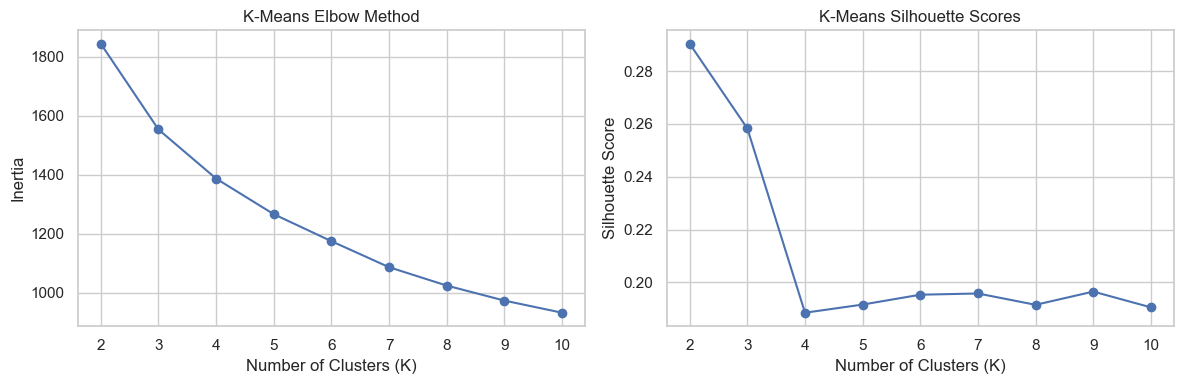

In [13]:
# Evaluating K-Means for different numbers of clusters

k_values = range(2, 11)

inertia_scores = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertia_scores.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Displaying results
kmeans_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_scores,
    "Silhouette Score": silhouette_scores
})

display(kmeans_results.round(4))

# Plotting elbow and silhouette results
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertia_scores, marker="o")
axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

### 2.1 K-Means Cluster Selection

K-Means clustering was evaluated for K = 2 to K = 10 using inertia and silhouette scores. Inertia decreased consistently as the number of clusters increased, without a clearly defined elbow. The highest silhouette score (0.2903) was obtained at K = 2, followed by K = 3 (0.2583). Consequently, K = 2 was provisionally selected as the preferred solution. However, the relatively modest silhouette score suggests overlapping customer spending patterns, requiring further assessment of cluster sizes and interpretability.

In [14]:
# Fitting the selected K-Means model
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_scaled)

# Examining cluster sizes
cluster_sizes = pd.Series(
    kmeans_labels,
    name="Cluster"
).value_counts().sort_index()

print("K-Means Cluster Sizes:")
display(cluster_sizes.to_frame("Customers"))

# Evaluating clustering quality
print("Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 4))

print("Davies-Bouldin Index:",
      round(davies_bouldin_score(X_scaled, kmeans_labels), 4))

# Examining average spending by cluster
kmeans_profile = df[spending_cols].copy()
kmeans_profile["Cluster"] = kmeans_labels

print("\nMedian Annual Spending by Cluster:")
display(
    kmeans_profile.groupby("Cluster")[spending_cols]
    .median()
    .round(2)
)

K-Means Cluster Sizes:


,Customers
Cluster,
0,252
1,188


Silhouette Score: 0.2903
Davies-Bouldin Index: 1.3515

Median Annual Spending by Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,10347.5,1871.0,2406.0,2225.0,327.5,749.5
1,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5


### 2.2 K-Means Clustering Results

The two-cluster K-Means solution divided the 440 customers into Cluster 0 (252 customers; 57.3%) and Cluster 1 (188 customers; 42.7%). Cluster 0 exhibited higher median expenditure on Fresh (10,347.5 m.u.) and Frozen products (2,225.0 m.u.), while Cluster 1 spent considerably more on Milk (7,690.5 m.u.), Grocery (11,527.0 m.u.), and Detergents_Paper (4,495.0 m.u.). The silhouette score of 0.2903 and Davies–Bouldin index of 1.3515 indicate modest cluster separation. Nevertheless, the clusters reveal potentially useful differences in purchasing behaviour that can inform customer segmentation.

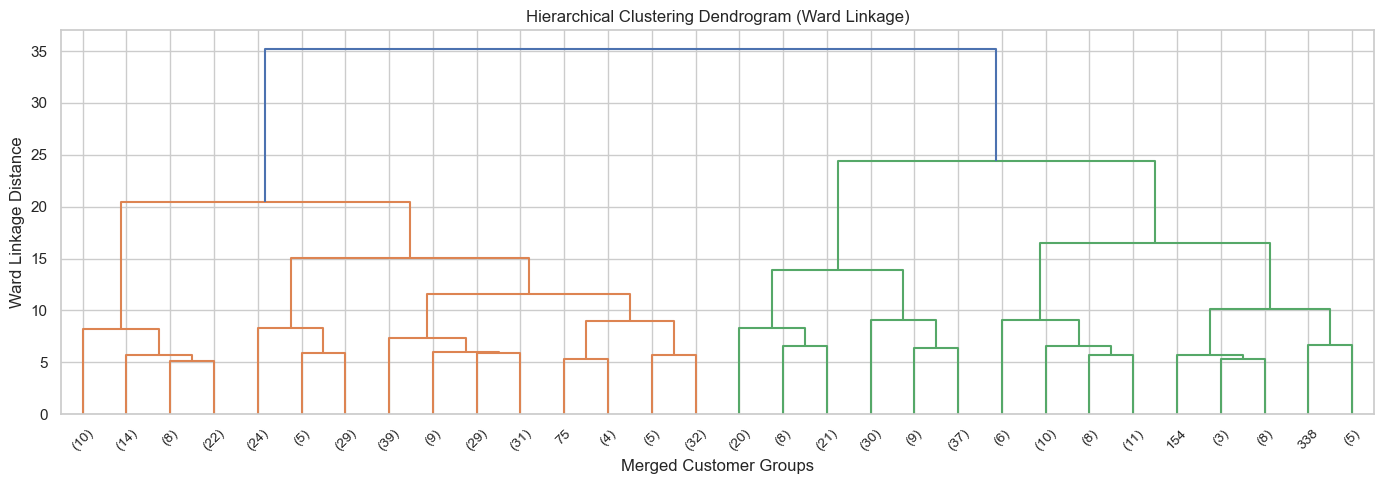

In [15]:
# Hierarchical clustering using Ward linkage
Z = linkage(X_scaled, method="ward")

# Plotting dendrogram
plt.figure(figsize=(14, 5))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)")
plt.xlabel("Merged Customer Groups")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

### 2.3 Hierarchical Clustering

Agglomerative hierarchical clustering was examined using Ward linkage on the standardized spending variables. The dendrogram shows two major customer groups, which merge at a linkage distance of approximately 35.2. This relatively large final merging distance supports investigating a two-cluster solution, consistent with the K-Means findings. However, smaller branches indicate possible subgroups, making it necessary to compare alternative cluster numbers using quantitative evaluation measures.

In [16]:
# Evaluating hierarchical clustering for different cluster numbers

hierarchical_results = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels)
    })

hierarchical_results = pd.DataFrame(hierarchical_results)

display(hierarchical_results.round(4))

,K,Silhouette Score,Davies-Bouldin Index
0,2,0.2585,1.6004
1,3,0.2547,1.5390
2,4,0.2021,1.5211
3,5,0.2025,1.3862
4,6,0.1707,1.4895
5,7,0.1633,1.4983
6,8,0.1482,1.5865
7,9,0.1555,1.5492
8,10,0.1218,1.5012


### 2.4 Hierarchical Clustering Evaluation

Hierarchical clustering was evaluated for 2–10 clusters using silhouette scores and the Davies–Bouldin index. The highest silhouette score (0.2585) occurred at K = 2, while the lowest Davies–Bouldin index (1.3862) occurred at K = 5. A two-cluster solution was provisionally selected because it achieved the strongest silhouette score and was consistent with the dendrogram. Compared with K-Means at K = 2, hierarchical clustering produced a lower silhouette score (0.2585 versus 0.2903) and a higher Davies–Bouldin index (1.6004 versus 1.3515), indicating weaker separation under these measures.

In [17]:
# Fitting hierarchical clustering with two clusters
hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Cluster sizes
print("Hierarchical Cluster Sizes:")
display(
    pd.Series(hierarchical_labels)
    .value_counts()
    .sort_index()
    .to_frame("Customers")
)

# Median spending profiles
hierarchical_profile = df[spending_cols].copy()
hierarchical_profile["Cluster"] = hierarchical_labels

print("\nMedian Annual Spending by Cluster:")
display(
    hierarchical_profile
    .groupby("Cluster")[spending_cols]
    .median()
    .round(2)
)

# Comparing agreement between K-Means and Hierarchical Clustering
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    kmeans_labels,
    hierarchical_labels
)

print(f"\nAdjusted Rand Index: {ari:.4f}")

Hierarchical Cluster Sizes:


,Customers
0,178
1,262



Median Annual Spending by Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,4499.5,7339.0,11099.0,957.0,4584.0,1189.0
1,11113.0,2028.0,2583.5,2382.0,358.5,864.0



Adjusted Rand Index: 0.6389


### 2.5 Hierarchical Cluster Profiles and Agreement

The selected hierarchical clustering solution divided customers into two groups containing 178 (40.5%) and 262 (59.5%) observations. Cluster 0 exhibited higher median expenditure on Milk, Grocery, Detergents_Paper, and Delicatessen products, while Cluster 1 recorded higher expenditure on Fresh and Frozen products. These profiles closely resemble the K-Means segments, although their numerical labels are reversed. The Adjusted Rand Index of 0.6389 indicates substantial agreement between the two algorithms, supporting the consistency of the broad spending patterns identified. However, the imperfect agreement suggests some uncertainty in individual customer assignments.

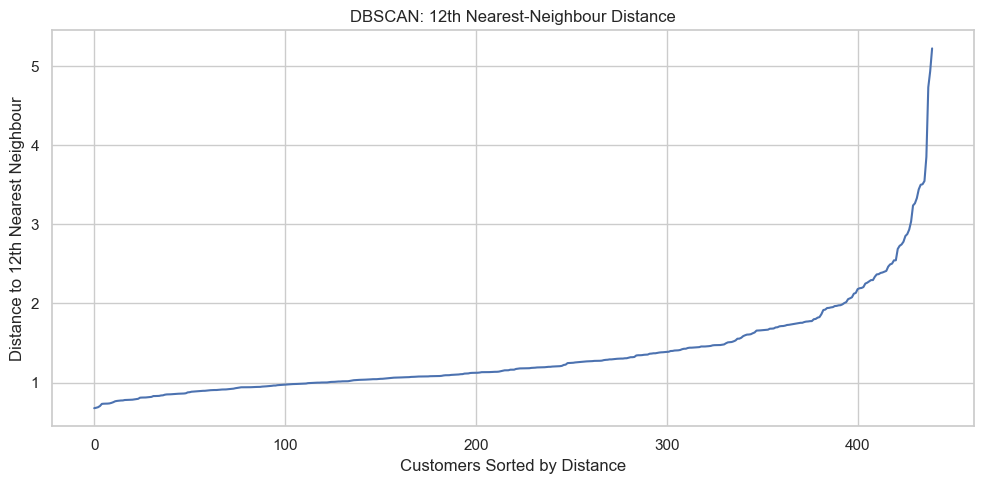

In [18]:
from sklearn.neighbors import NearestNeighbors

# Initial DBSCAN parameter
min_samples = 12

# Finding distances to the 12th nearest neighbour
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sorting the distances
k_distances = np.sort(distances[:, -1])

# Plotting the k-distance graph
plt.figure(figsize=(10, 5))

plt.plot(k_distances)
plt.title("DBSCAN: 12th Nearest-Neighbour Distance")
plt.xlabel("Customers Sorted by Distance")
plt.ylabel("Distance to 12th Nearest Neighbour")

plt.tight_layout()
plt.show()

### 2.6 DBSCAN Parameter Selection

DBSCAN parameter selection was guided by a 12th-nearest-neighbour distance plot, using an initial `min_samples` value of 12. The curve increases gradually for most observations before rising more sharply at distances of approximately 2.0–2.5. This suggests a possible neighbourhood radius within that range. However, because the graph does not show a sharply defined elbow, several combinations of `eps` and `min_samples` will be evaluated to assess cluster quality and the proportion of customers classified as noise.

In [19]:
# Evaluating DBSCAN parameter combinations

dbscan_results = []

for eps in np.arange(1.5, 3.1, 0.25):
    for min_samples in [6, 12, 18]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        # Identifying non-noise observations
        mask = labels != -1

        # Number of clusters, excluding noise
        n_clusters = len(set(labels[mask]))

        # Percentage classified as noise
        noise_pct = 100 * (~mask).mean()

        # Evaluating only when at least two valid clusters exist
        if n_clusters >= 2 and mask.sum() > n_clusters:

            sil = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )

            dbi = davies_bouldin_score(
                X_scaled[mask],
                labels[mask]
            )

        else:
            sil = np.nan
            dbi = np.nan

        dbscan_results.append({
            "eps": round(eps, 2),
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise (%)": noise_pct,
            "Silhouette Score": sil,
            "Davies-Bouldin Index": dbi
        })

dbscan_results = pd.DataFrame(dbscan_results)

display(
    dbscan_results.round(4)
)

,eps,min_samples,Clusters,Noise (%),Silhouette Score,Davies-Bouldin Index
0,1.50,6,1,9.3182,NaN,NaN
1,1.50,12,1,11.5909,NaN,NaN
2,1.50,18,1,14.0909,NaN,NaN
3,1.75,6,1,5.9091,NaN,NaN
4,1.75,12,1,6.8182,NaN,NaN
5,1.75,18,1,7.2727,NaN,NaN
6,2.00,6,1,3.4091,NaN,NaN
7,2.00,12,1,3.8636,NaN,NaN
8,2.00,18,1,4.3182,NaN,NaN
9,2.25,6,1,1.5909,NaN,NaN


### 2.7 Initial DBSCAN Evaluation

DBSCAN was evaluated using 21 combinations of neighbourhood radius (`eps` = 1.5–3.0) and minimum neighbourhood size (`min_samples` = 6, 12, and 18). All configurations produced a single cluster, with noise proportions ranging from approximately 0.68% to 14.09%. Consequently, silhouette and Davies–Bouldin scores were undefined because at least two clusters are required for these evaluations. The results suggest that the selected neighbourhood radii connect most customers into one density-based group. A further examination of smaller `eps` values is therefore necessary before assessing DBSCAN's suitability for customer segmentation.

In [20]:
# Exploring smaller DBSCAN neighbourhoods

dbscan_refined = []

for eps in np.arange(0.5, 1.51, 0.1):
    for min_samples in [4, 6, 8, 12]:

        model = DBSCAN(
            eps=round(eps, 2),
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        noise_pct = 100 * (~mask).mean()

        # Size of the largest non-noise cluster
        cluster_sizes = pd.Series(labels[mask]).value_counts()
        largest_cluster = (
            int(cluster_sizes.max())
            if not cluster_sizes.empty else 0
        )

        # Evaluating only valid multi-cluster solutions
        if n_clusters >= 2 and mask.sum() > n_clusters:
            sil = silhouette_score(
                X_scaled[mask], labels[mask]
            )
            dbi = davies_bouldin_score(
                X_scaled[mask], labels[mask]
            )
        else:
            sil = np.nan
            dbi = np.nan

        dbscan_refined.append({
            "eps": round(eps, 2),
            "min_samples": min_samples,
            "Clusters": n_clusters,
            "Noise (%)": noise_pct,
            "Largest Cluster": largest_cluster,
            "Silhouette Score": sil,
            "Davies-Bouldin Index": dbi
        })

dbscan_refined = pd.DataFrame(dbscan_refined)

# Displaying configurations producing at least two clusters
multi_cluster_results = dbscan_refined[
    dbscan_refined["Clusters"] >= 2
].copy()

print("DBSCAN configurations producing multiple clusters:")
display(multi_cluster_results.round(4))

print("\nTotal configurations tested:", len(dbscan_refined))
print("Configurations with multiple clusters:", len(multi_cluster_results))

DBSCAN configurations producing multiple clusters:


,eps,min_samples,Clusters,Noise (%),Largest Cluster,Silhouette Score,Davies-Bouldin Index
0,0.5,4,6,94.3182,5,0.4386,0.7304
4,0.6,4,7,84.5455,22,0.3129,1.0052
5,0.6,6,3,92.7273,18,0.5994,0.6193
8,0.7,4,13,66.3636,60,0.1058,1.0210
9,0.7,6,5,82.9545,36,0.2452,1.1539
10,0.7,8,3,90.2273,24,0.5533,0.6953
12,0.8,4,5,47.0455,216,-0.0379,0.9062
13,0.8,6,3,59.5455,88,0.3242,1.0025
14,0.8,8,2,66.5909,77,0.5072,0.7698
15,0.8,12,2,78.6364,50,0.5517,0.6903



Total configurations tested: 44
Configurations with multiple clusters: 17


### 2.8 Refined DBSCAN Evaluation

A refined DBSCAN search evaluated 44 combinations of `eps` (0.5–1.5) and `min_samples` (4, 6, 8, and 12). Seventeen configurations produced multiple clusters. The highest silhouette score (0.5994) occurred at `eps=0.6` and `min_samples=6`, but approximately 92.73% of customers were classified as noise. Configurations retaining more customers generally produced weaker cluster separation. For example, `eps=1.1` and `min_samples=4` classified 18.64% of customers as noise but achieved a silhouette score of only 0.1541. These findings suggest that DBSCAN is less suitable for comprehensive customer segmentation under the tested settings, although it may be useful for identifying unusual spending patterns. Its noise-excluded evaluation scores are not directly comparable with the full-sample scores of K-Means and hierarchical clustering.

In [21]:
# Fitting a representative DBSCAN model
dbscan = DBSCAN(eps=1.0, min_samples=6)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Examining cluster sizes, including noise
print("DBSCAN Cluster Sizes:")
display(
    pd.Series(dbscan_labels, name="Cluster")
    .value_counts()
    .sort_index()
    .to_frame("Customers")
)

# Comparing clustering algorithms
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],
    "Clusters": [
        2,
        2,
        len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    ],
    "Noise (%)": [
        0,
        0,
        100 * np.mean(dbscan_labels == -1)
    ],
    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, hierarchical_labels),
        silhouette_score(
            X_scaled[dbscan_labels != -1],
            dbscan_labels[dbscan_labels != -1]
        )
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, hierarchical_labels),
        davies_bouldin_score(
            X_scaled[dbscan_labels != -1],
            dbscan_labels[dbscan_labels != -1]
        )
    ]
})

display(comparison.round(4))

DBSCAN Cluster Sizes:


,Customers
Cluster,
-1,129
0,300
1,11


,Algorithm,Clusters,Noise (%),Silhouette Score,Davies-Bouldin Index
0,K-Means,2,0.0000,0.2903,1.3515
1,Hierarchical,2,0.0000,0.2585,1.6004
2,DBSCAN,2,29.3182,0.2538,0.8878


### 2.9 Comparative Evaluation and Algorithm Selection

Three clustering approaches were compared using log-transformed and standardized customer spending data. K-Means achieved the highest full-sample silhouette score (0.2903) and a Davies–Bouldin index of 1.3515, outperforming hierarchical clustering (0.2585 and 1.6004, respectively). Both methods identified two broadly similar customer groups, with an Adjusted Rand Index of 0.6389. DBSCAN, using `eps=1.0` and `min_samples=6`, identified two clusters containing 300 and 11 customers, while classifying 129 customers (29.32%) as noise. Although DBSCAN achieved a lower Davies–Bouldin index (0.8878), this was calculated only on non-noise observations and is therefore not directly comparable with the full-sample results.

K-Means was selected as the preferred approach because it assigns all customers to reasonably balanced groups, provides better separation than hierarchical clustering under the selected metrics, and produces interpretable spending profiles. Nevertheless, its modest silhouette score indicates some overlap between customer segments. DBSCAN may be more appropriate for identifying unusual spending patterns than for comprehensive customer segmentation.

In [22]:
# Creating a dataset containing the selected K-Means clusters
segmented_df = df.copy()
segmented_df["Cluster"] = kmeans_labels

# Examining customer distribution by Channel
print("Customer Distribution by Channel (%):")

channel_distribution = pd.crosstab(
    segmented_df["Cluster"],
    segmented_df["Channel"],
    normalize="index"
) * 100

display(channel_distribution.round(2))

# Examining customer distribution by Region
print("\nCustomer Distribution by Region (%):")

region_distribution = pd.crosstab(
    segmented_df["Cluster"],
    segmented_df["Region"],
    normalize="index"
) * 100

display(region_distribution.round(2))

# Calculating total annual spending per customer
segmented_df["Total_Spending"] = segmented_df[spending_cols].sum(axis=1)

# Examining median total spending by cluster
print("\nMedian Total Annual Spending by Cluster:")

display(
    segmented_df.groupby("Cluster")["Total_Spending"]
    .agg(["count", "median", "mean"])
    .round(2)
)

Customer Distribution by Channel (%):


Channel,1,2
Cluster,,
0,96.83,3.17
1,28.72,71.28



Customer Distribution by Region (%):


Region,1,2,3
Cluster,,,
0,19.05,11.11,69.84
1,15.43,10.11,74.47



Median Total Annual Spending by Cluster:


,count,median,mean
Cluster,,,
0,252,19745.0,24529.24
1,188,35222.5,44883.68


### 3.1 Customer Segment Characteristics

The selected K-Means solution identified two customer segments with distinct spending patterns. Cluster 0 comprises 252 customers (57.3%) and is characterized by higher expenditure on Fresh and Frozen products. Approximately 96.83% of these customers belong to Channel 1 (Horeca), suggesting a strong association with hotels, restaurants, and cafés. Cluster 1 contains 188 customers (42.7%) and exhibits higher expenditure on Milk, Grocery, Detergents_Paper, and Delicatessen products. Approximately 71.28% belong to Channel 2 (Retail). Cluster 1 also records higher median total annual spending (35,222.5 m.u.) than Cluster 0 (19,745.0 m.u.).

Both segments have broadly similar geographical distributions, with Region 3 accounting for approximately 70–74% of customers. These findings suggest that customer spending patterns are more closely associated with distribution channels than geographical location. However, the segments represent observed purchasing behaviour rather than definitive customer identities or profitability classifications.

### 3.2 Customer Segmentation and Business Recommendations

**Segment 1: Fresh and Frozen-Oriented Horeca Customers (Cluster 0)**

This segment contains 252 customers (57.3%) and is characterized by relatively high spending on Fresh and Frozen products. Most customers belong to the Horeca channel. The distributor should prioritize reliable delivery schedules, cold-chain logistics, flexible ordering arrangements, and targeted discounts on frequently purchased fresh products. These strategies could improve service reliability and customer retention.

**Segment 2: Grocery and Household-Oriented Retail Customers (Cluster 1)**

This segment comprises 188 customers (42.7%) and exhibits higher expenditure on Milk, Grocery, Detergents_Paper, and Delicatessen products. Most customers belong to the Retail channel, and the segment records higher median total annual spending. Recommended strategies include bulk purchasing incentives, loyalty programmes, bundled promotions, and efficient inventory replenishment. These interventions could strengthen customer relationships and increase repeat purchases.

The proposed strategies are based on observed expenditure patterns and should be tested against customer preferences, profitability, and operational constraints before implementation.

In [23]:
# Robustness assessment of K-Means clustering

from sklearn.metrics import adjusted_rand_score

# Alternative 1: Standardization without log transformation
X_standard_only = StandardScaler().fit_transform(
    df[spending_cols]
)

# Alternative 2: Log transformation followed by RobustScaler
X_log_robust = RobustScaler().fit_transform(
    np.log1p(df[spending_cols])
)

# Fitting K-Means using both alternatives
km_standard = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
).fit_predict(X_standard_only)

km_robust = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
).fit_predict(X_log_robust)

# Comparing with the original clustering solution
robustness_results = pd.DataFrame({
    "Preprocessing Method": [
        "Log + StandardScaler (Original)",
        "StandardScaler Only",
        "Log + RobustScaler"
    ],
    "Silhouette Score": [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_standard_only, km_standard),
        silhouette_score(X_log_robust, km_robust)
    ],
    "ARI vs Original": [
        1.0,
        adjusted_rand_score(kmeans_labels, km_standard),
        adjusted_rand_score(kmeans_labels, km_robust)
    ]
})

display(robustness_results.round(4))

,Preprocessing Method,Silhouette Score,ARI vs Original
0,Log + StandardScaler (Original),0.2903,1.0000
1,StandardScaler Only,0.6137,0.0813
2,Log + RobustScaler,0.2529,0.9284


### 3.3 Robustness Assessment

A robustness assessment compared the selected K-Means solution with two alternative preprocessing approaches. StandardScaler without logarithmic transformation produced a higher silhouette score (0.6137), but very low agreement with the original segmentation (ARI = 0.0813). This suggests that the resulting customer assignments differ substantially, potentially because extreme spending values exert greater influence without logarithmic transformation.

Logarithmic transformation followed by RobustScaler produced a silhouette score of 0.2529 and a high Adjusted Rand Index of 0.9284 relative to the original model. This indicates that customer assignments are largely consistent across the two scaling approaches when logarithmic transformation is retained.

Overall, the results suggest that the segmentation is relatively robust to the choice of scaler but sensitive to whether logarithmic transformation is applied. The original Log + StandardScaler approach was retained because it reduces the influence of extreme expenditure values while producing reasonably balanced and interpretable customer segments.

In [24]:
# Comparing cluster sizes across preprocessing methods

cluster_size_comparison = pd.DataFrame({
    "Original Log + StandardScaler": pd.Series(kmeans_labels).value_counts().sort_index(),
    "StandardScaler Only": pd.Series(km_standard).value_counts().sort_index(),
    "Log + RobustScaler": pd.Series(km_robust).value_counts().sort_index()
})

display(cluster_size_comparison)

,Original Log + StandardScaler,StandardScaler Only,Log + RobustScaler
0,252,36,252
1,188,404,188


## 4. Conclusion

This project applied unsupervised machine learning to segment 440 wholesale customers according to their annual expenditure across six product categories. Exploratory analysis revealed substantial differences in spending and strong positive skewness, justifying logarithmic transformation and standardization. A Hopkins statistic of 0.7924 provided evidence of cluster tendency.

Three clustering algorithms were evaluated: K-Means, Agglomerative Hierarchical Clustering, and DBSCAN. K-Means with two clusters was selected as the preferred approach, achieving a silhouette score of 0.2903 and a Davies–Bouldin index of 1.3515. Hierarchical clustering identified broadly similar spending patterns, while DBSCAN either produced a single cluster or excluded substantial proportions of customers as noise.

The selected K-Means model identified two customer segments. The first comprised 252 customers (57.3%) with relatively higher spending on Fresh and Frozen products, predominantly associated with the Horeca channel. The second comprised 188 customers (42.7%) with higher spending on Milk, Grocery, Detergents_Paper, and Delicatessen products, predominantly associated with the Retail channel.

The findings support differentiated business strategies, including improved fresh-product delivery and cold-chain logistics for the first segment, and bulk purchasing incentives, loyalty programmes, and inventory replenishment for the second.

Robustness analysis showed that removing logarithmic transformation produced highly unbalanced clusters (36 versus 404 customers), despite achieving a higher silhouette score. In contrast, logarithmic transformation followed by RobustScaler produced highly similar customer assignments (ARI = 0.9284). This supports retaining the original preprocessing approach.

Overall, the analysis demonstrates how clustering can support customer segmentation and targeted distribution strategies. However, the modest silhouette score indicates overlapping customer characteristics, and the proposed business strategies should be validated before implementation.